In [13]:
# Cell 1: imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_predict, LeaveOneOut


In [14]:
# Cell 2: load and inspect Data
df = pd.read_csv("house_prices.csv")
print(df.shape)   # (rows, columns)


(10, 2)


In [15]:
# # both columns should be numbers (int64), with no missing values

df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Size    10 non-null     int64
 1   Price   10 non-null     int64
dtypes: int64(2)
memory usage: 288.0 bytes


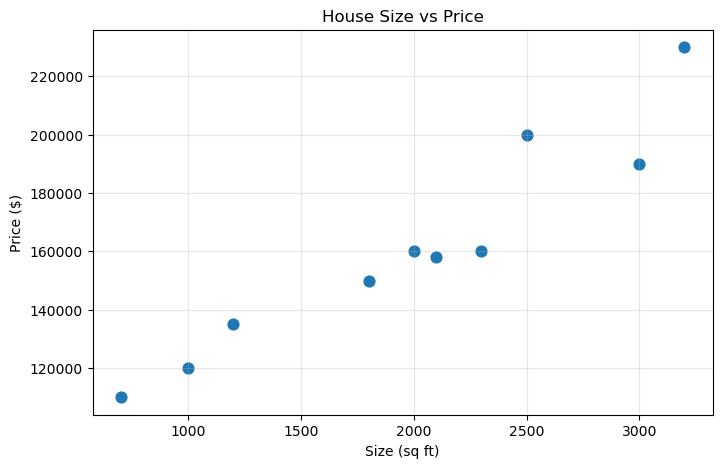

In [16]:
# Do bigger houses always cost more? Do you think the points will form a straight line, a curve, or no pattern? Make a guess, then run the cell.
plt.figure(figsize=(8, 5))
plt.scatter(df["Size"], df["Price"], s=60)
plt.xlabel("Size (sq ft)")
plt.ylabel("Price ($)")
plt.title("House Size vs Price")
plt.grid(alpha=0.3)
plt.show()


In [17]:
# Train the model

X = df[["Size"]]
y = df["Price"]

model = LinearRegression()
model.fit(X, y)

print("Slope (price per sq ft):", round(model.coef_[0], 2))
print("Intercept:", round(model.intercept_, 2))


Slope (price per sq ft): 42.41
Intercept: 77333.33


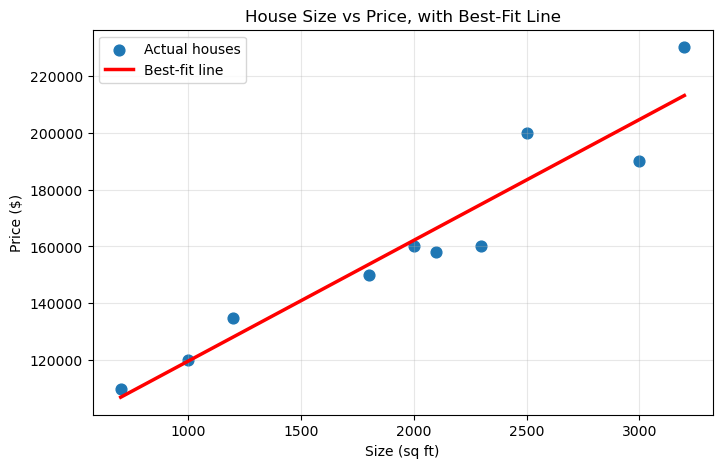

In [18]:
#best fit line
line_x = pd.DataFrame({"Size": np.linspace(df["Size"].min(), df["Size"].max(), 100)})
line_y = model.predict(line_x)

plt.figure(figsize=(8, 5))
plt.scatter(df["Size"], df["Price"], s=60, label="Actual houses")
plt.plot(line_x["Size"], line_y, color="red", linewidth=2.5, label="Best-fit line")
plt.xlabel("Size (sq ft)")
plt.ylabel("Price ($)")
plt.title("House Size vs Price, with Best-Fit Line")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [19]:
#Make a prediction for 1500sqft house
new_house = pd.DataFrame({"Size": [1500]})
print("Predicted price for 1,500 sq ft: $", round(model.predict(new_house)[0]))

Predicted price for 1,500 sq ft: $ 140944


In [21]:
#model used least squares formulas:
x_mean = df["Size"].mean()
y_mean = df["Price"].mean()

slope = ((df["Size"] - x_mean) * (df["Price"] - y_mean)).sum() / ((df["Size"] - x_mean) ** 2).sum()
intercept = y_mean - slope * x_mean

print(f"Average size: {x_mean:,.0f} sq ft   Average price: ${y_mean:,.0f}")
print(f"Hand-calculated slope:     {slope:.2f}   scikit-learn: {model.coef_[0]:.2f}")
print(f"Hand-calculated intercept: {intercept:,.2f}   scikit-learn: {model.intercept_:,.2f}")



Average size: 1,980 sq ft   Average price: $161,300
Hand-calculated slope:     42.41   scikit-learn: 42.41
Hand-calculated intercept: 77,333.33   scikit-learn: 77,333.33


In [22]:
#how good is this model

print("R² on all 10 houses:", round(model.score(X, y), 3))

loo_preds = cross_val_predict(LinearRegression(), X, y, cv=LeaveOneOut())
print("Leave-one-out average error: $", round(mean_absolute_error(y, loo_preds)))
print("Leave-one-out R²:", round(r2_score(y, loo_preds), 3))


R² on all 10 houses: 0.907
Leave-one-out average error: $ 11131
Leave-one-out R²: 0.842


In [ ]:
#Size explains about **91%** of the variation in price, a strong fit.